# Expected goals (xG) model

A logistic regression that gives the probability that a shot is scored, now with the **body part** used:

$$p(\text{goal}) = \sigma(\beta_0 + \beta_1 d + \beta_2 \theta + \beta_3 b)$$

where $d$ is the distance to goal, $\theta$ the shooting angle and $b$ is 1 for headers.

In [ ]:
import pandas as pd
from sklearn.linear_model import LogisticRegression

In [ ]:
shots = pd.read_parquet("shots.parquet")
shots["header"] = (shots["body_part"] == "head").astype(int)
X, y = shots[["distance", "angle", "header"]], shots["goal"]

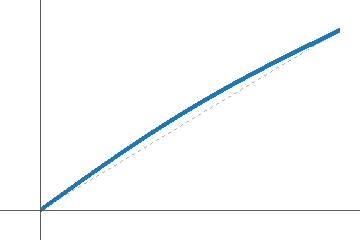

In [1]:
model = LogisticRegression(C=1.0, max_iter=500)
model.fit(X, y)
plot_calibration(model, X, y)

## Headers

Headers are scored less often than shots with the foot from the same spot, so the model needs the body part.

In [1]:
shots.groupby("shot_type").agg(shots=("goal", "size"), goals=("goal", "sum"), mean_xG=("xG", "mean"))

,shot_type,shots,goals,mean_xG
0,foot,8412,903,0.108
1,header,1730,141,0.083
2,other,212,19,0.091


In [1]:
scores = cross_val_score(model, X, y, cv=5, scoring="neg_log_loss")
print(scores.mean())

-0.2794
